# Task 2

### Interpolate for NaN, gpr with a kernel

In [1]:
# This serves as a template which will guide you through the implementation of this task.  It is advised
# to first read the whole template and get a sense of the overall structure of the code before trying to fill in any of the TODO gaps
# First, we import necessary libraries:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, RBF, Matern, RationalQuadratic, ExpSineSquared, ConstantKernel

def data_loading():
    """
    This function loads the training and test data, preprocesses it, removes the NaN values and interpolates the missing 
    data using imputation

    Parameters
    ----------
    Returns
    ----------
    X_train: matrix of floats, training input with features
    y_train: array of floats, training output with labels
    X_test: matrix of floats: dim = (100, ?), test input with features
    """
    # Load training data
    train_df = pd.read_csv("train.csv")
    
    print("Training data:")
    print("Shape:", train_df.shape)
    print(train_df.head(2))
    print('\n')
    
    # Load test data
    test_df = pd.read_csv("test.csv")

    print("Test data:")
    print(test_df.shape)
    print(test_df.head(2))

    # Dummy initialization of the X_train, X_test and y_train   
    X_train = np.zeros_like(train_df.drop(['price_CHF'],axis=1))
    y_train = np.zeros_like(train_df['price_CHF'])
    X_test = np.zeros_like(test_df)

    # TODO: Perform data preprocessing, imputation and extract X_train, y_train and X_test
    
    # Use mean values for NaN
    # train_filled_df = train_df.fillna(train_df.mean())
    # test_filled_df = test_df.fillna(test_df.mean())
    
    # Use interpolated values for NaN
    train_filled_df = train_df.interpolate(limit_direction="both")
    test_filled_df = test_df.interpolate(limit_direction="both")

    # Preprocessing: Encode season attributes using OneHotEncoder
    encoder_train = OneHotEncoder(handle_unknown='ignore')
    encoder_test = OneHotEncoder(handle_unknown='ignore')

    encoder_train_df = pd.DataFrame(encoder_train.fit_transform(train_filled_df[['season']]).toarray())
    encoder_test_df = pd.DataFrame(encoder_test.fit_transform(test_filled_df[['season']]).toarray())

    train_filled_df.drop(['season'], axis=1, inplace=True)
    test_filled_df.drop(['season'], axis=1, inplace=True)

    encoder_train_df.columns = encoder_train.get_feature_names_out()
    encoder_test_df.columns = encoder_test.get_feature_names_out()

    train_final_df = pd.concat([encoder_train_df, train_filled_df], axis=1)
    test_final_df = pd.concat([encoder_test_df, test_filled_df], axis=1)
    
    X_train = train_final_df.drop(['price_CHF'],axis=1).to_numpy()
    y_train = train_final_df['price_CHF'].to_numpy()
    X_test = test_final_df.to_numpy()

    assert (X_train.shape[1] == X_test.shape[1]) and (X_train.shape[0] == y_train.shape[0]) and (X_test.shape[0] == 100), "Invalid data shape"
    return X_train, y_train, X_test

def modeling_and_prediction(X_train, y_train, X_test):
    """
    This function defines the model, fits training data and then does the prediction with the test data 

    Parameters
    ----------
    X_train: matrix of floats, training input with 10 features
    y_train: array of floats, training output
    X_test: matrix of floats: dim = (100, ?), test input with 10 features

    Returns
    ----------
    y_test: array of floats: dim = (100,), predictions on test set
    """

    y_pred=np.zeros(X_test.shape[0])
    #TODO: Define the model and fit it using training data. Then, use test data to make predictions

    kernel = RationalQuadratic() * DotProduct()
    gpr = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5)
    gpr.fit(X_train, y_train)
    
    y_pred = gpr.predict(X_test)
    
    assert y_pred.shape == (100,), "Invalid data shape"
    return y_pred

# Main function. You don't have to change this
if __name__ == "__main__":
    # Data loading
    X_train, y_train, X_test = data_loading()
    # The function retrieving optimal LR parameters
    y_pred=modeling_and_prediction(X_train, y_train, X_test)
    # Save results in the required format
    dt = pd.DataFrame(y_pred) 
    dt.columns = ['price_CHF']
    dt.to_csv('results.csv', index=False)
    print("\nResults file successfully generated!")



Training data:
Shape: (900, 11)
   season  price_AUS  price_CHF  price_CZE  price_GER  price_ESP  price_FRA  \
0  spring        NaN   9.644028  -1.686248  -1.748076  -3.666005        NaN   
1  summer        NaN   7.246061  -2.132377  -2.054363  -3.295697  -4.104759   

   price_UK  price_ITA  price_POL  price_SVK  
0 -1.822720  -3.931031        NaN  -3.238197  
1 -1.826021        NaN        NaN  -3.212894  


Test data:
(100, 10)
   season  price_AUS  price_CZE  price_GER  price_ESP  price_FRA  price_UK  \
0  spring        NaN   0.472985   0.707957        NaN  -1.136441 -0.596703   
1  summer  -1.184837   0.358019        NaN  -3.199028  -1.069695       NaN   

   price_ITA  price_POL  price_SVK  
0        NaN   3.298693   1.921886  
1  -1.420091   3.238307        NaN  

Results file successfully generated!


### Interpolate for NaN, gpr with using CV to find kernel (not used)

In [2]:
# This serves as a template which will guide you through the implementation of this task.  It is advised
# to first read the whole template and get a sense of the overall structure of the code before trying to fill in any of the TODO gaps
# First, we import necessary libraries:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import DotProduct, RBF, Matern, RationalQuadratic, ExpSineSquared, ConstantKernel, CompoundKernel

def data_loading():
    """
    This function loads the training and test data, preprocesses it, removes the NaN values and interpolates the missing 
    data using imputation

    Parameters
    ----------
    Returns
    ----------
    X_train: matrix of floats, training input with features
    y_train: array of floats, training output with labels
    X_test: matrix of floats: dim = (100, ?), test input with features
    """
    # Load training data
    train_df = pd.read_csv("train.csv")
    
    print("Training data:")
    print("Shape:", train_df.shape)
    print(train_df.head(2))
    print('\n')
    
    # Load test data
    test_df = pd.read_csv("test.csv")

    print("Test data:")
    print(test_df.shape)
    print(test_df.head(2))

    # Dummy initialization of the X_train, X_test and y_train   
    X_train = np.zeros_like(train_df.drop(['price_CHF'],axis=1))
    y_train = np.zeros_like(train_df['price_CHF'])
    X_test = np.zeros_like(test_df)

    # TODO: Perform data preprocessing, imputation and extract X_train, y_train and X_test
    
    # Use mean values for NaN
    # train_filled_df = train_df.fillna(train_df.mean())
    # test_filled_df = test_df.fillna(test_df.mean())
    
    # Use interpolated values for NaN
    train_filled_df = train_df.interpolate(limit_direction="both")
    test_filled_df = test_df.interpolate(limit_direction="both")

    # Preprocessing: Encode season attributes using OneHotEncoder
    encoder_train = OneHotEncoder(handle_unknown='ignore')
    encoder_test = OneHotEncoder(handle_unknown='ignore')

    encoder_train_df = pd.DataFrame(encoder_train.fit_transform(train_filled_df[['season']]).toarray())
    encoder_test_df = pd.DataFrame(encoder_test.fit_transform(test_filled_df[['season']]).toarray())

    train_filled_df.drop(['season'], axis=1, inplace=True)
    test_filled_df.drop(['season'], axis=1, inplace=True)

    encoder_train_df.columns = encoder_train.get_feature_names_out()
    encoder_test_df.columns = encoder_test.get_feature_names_out()

    train_final_df = pd.concat([encoder_train_df, train_filled_df], axis=1)
    test_final_df = pd.concat([encoder_test_df, test_filled_df], axis=1)
    
    X_train = train_final_df.drop(['price_CHF'],axis=1).to_numpy()
    y_train = train_final_df['price_CHF'].to_numpy()
    X_test = test_final_df.to_numpy()

    assert (X_train.shape[1] == X_test.shape[1]) and (X_train.shape[0] == y_train.shape[0]) and (X_test.shape[0] == 100), "Invalid data shape"
    return X_train, y_train, X_test

def modeling_and_prediction(X_train, y_train, X_test):
    """
    This function defines the model, fits training data and then does the prediction with the test data 

    Parameters
    ----------
    X_train: matrix of floats, training input with 10 features
    y_train: array of floats, training output
    X_test: matrix of floats: dim = (100, ?), test input with 10 features

    Returns
    ----------
    y_test: array of floats: dim = (100,), predictions on test set
    """

    y_pred=np.zeros(X_test.shape[0])
    #TODO: Define the model and fit it using training data. Then, use test data to make predictions

    k1 = RationalQuadratic()
    kernels = [k1]
    
    r2_scores = np.zeros((5, len(kernels)))
    for j, k in enumerate(kernels):
        kf = KFold(n_splits=5)
        for i, (train, test) in enumerate(kf.split(X_train)):
            gpr = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=4)
            gpr.fit(X_train[train], y_train[train])
            y_pred = gpr.predict(X_train[test])
            r2_scores[i, j] = r2_score(y_train[test], y_pred)
            
    avg_r2_scores = np.mean(r2_scores, axis=0)
    
    best_kernel = kernels[np.argmax(avg_r2_scores)]
    
    print(f"R2 scores: {avg_r2_scores}")
    print(f"Best R2 score is at index: {np.argmax(avg_r2_scores)}")
    
    gpr = GaussianProcessRegressor(kernel=best_kernel, n_restarts_optimizer=5)
    gpr.fit(X_train, y_train)
    
    y_pred = gpr.predict(X_test)
            
    assert y_pred.shape == (100,), "Invalid data shape"
    return y_pred

# Main function. You don't have to change this
if __name__ == "__main__":
    # Data loading
    X_train, y_train, X_test = data_loading()
    # The function retrieving optimal LR parameters
    y_pred=modeling_and_prediction(X_train, y_train, X_test)
    # Save results in the required format
    dt = pd.DataFrame(y_pred) 
    dt.columns = ['price_CHF']
    dt.to_csv('results.csv', index=False)
    print("\nResults file successfully generated!")



Training data:
Shape: (900, 11)
   season  price_AUS  price_CHF  price_CZE  price_GER  price_ESP  price_FRA  \
0  spring        NaN   9.644028  -1.686248  -1.748076  -3.666005        NaN   
1  summer        NaN   7.246061  -2.132377  -2.054363  -3.295697  -4.104759   

   price_UK  price_ITA  price_POL  price_SVK  
0 -1.822720  -3.931031        NaN  -3.238197  
1 -1.826021        NaN        NaN  -3.212894  


Test data:
(100, 10)
   season  price_AUS  price_CZE  price_GER  price_ESP  price_FRA  price_UK  \
0  spring        NaN   0.472985   0.707957        NaN  -1.136441 -0.596703   
1  summer  -1.184837   0.358019        NaN  -3.199028  -1.069695       NaN   

   price_ITA  price_POL  price_SVK  
0        NaN   3.298693   1.921886  
1  -1.420091   3.238307        NaN  
R2 scores: [0.95100746]
Best R2 score is at index: 0

Results file successfully generated!


### Analyzing data

<Axes: >

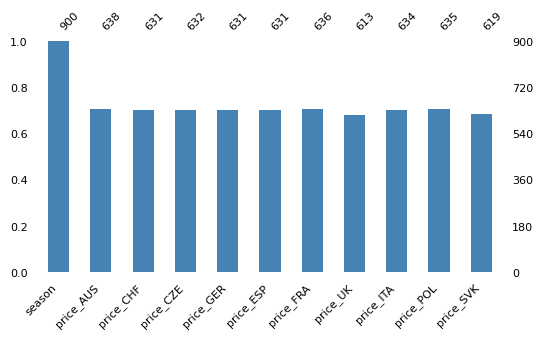

In [4]:
import missingno as msno
import matplotlib.pyplot as plt

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

msno.bar(train_df, figsize=(6, 3), fontsize=8, color='steelblue')

<Axes: >

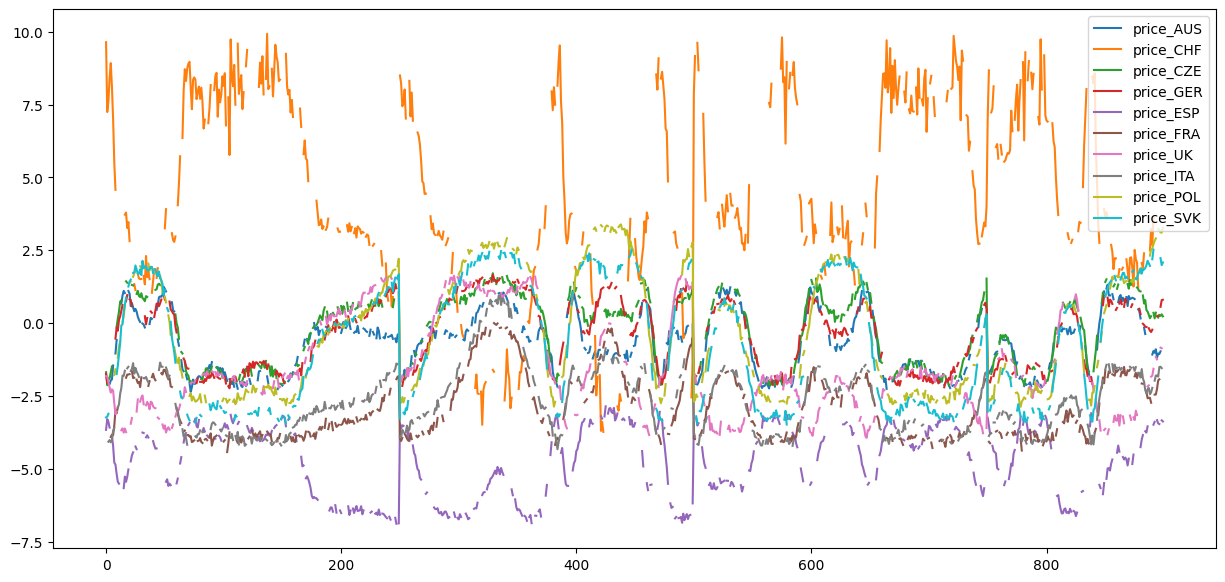

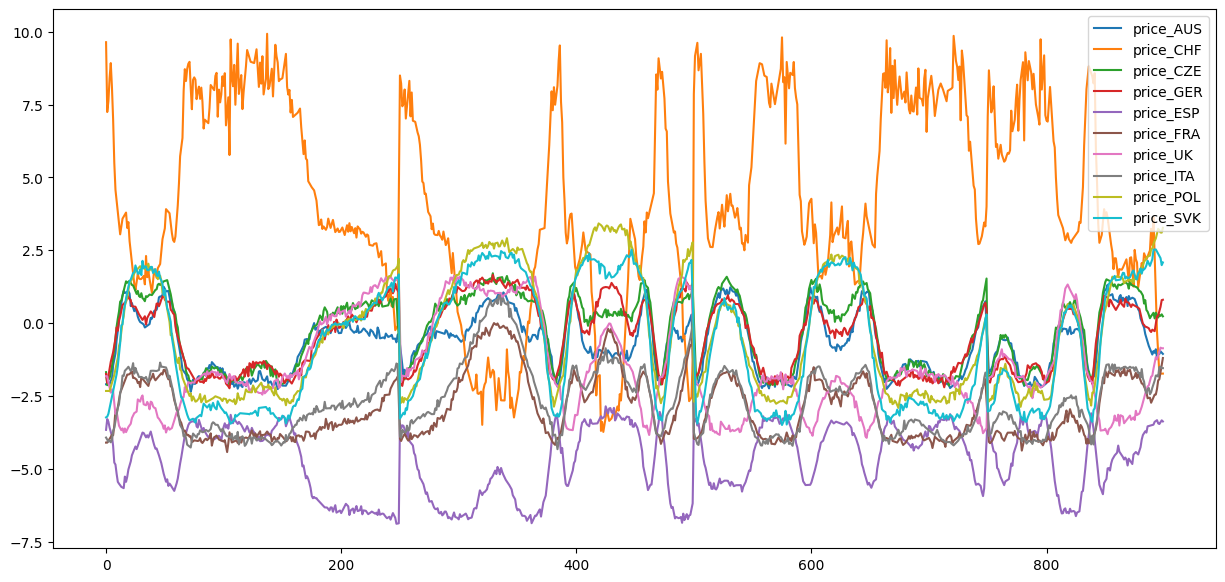

In [5]:
import matplotlib.pyplot as plt

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

plot_AUS = train_df[["season", "price_AUS"]]
plot_CHF = train_df[["season", "price_CHF"]]
plot_CZE = train_df[["season", "price_CZE"]]
plot_GER = train_df[["season", "price_GER"]]
plot_ESP = train_df[["season", "price_ESP"]]
plot_FRA = train_df[["season", "price_FRA"]]
plot_UK = train_df[["season", "price_UK"]]
plot_ITA = train_df[["season", "price_ITA"]]
plot_POL = train_df[["season", "price_POL"]]
plot_SVK = train_df[["season", "price_SVK"]]

#plot_AUS = train_df[["season", "price_AUS"]]
#plot_AUS.plot(figsize=(15,5))
#plot_AUS.interpolate(limit_direction="both").plot(figsize=(15,5))

train_filled_df = train_df.interpolate(limit_direction="both")
train_df.plot(figsize=(15,7))
train_filled_df.plot(figsize=(15,7))

In [6]:
train_df.mean()

/tmp/ipykernel_985/1834078839.py:1: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  train_df.mean()


price_AUS   -0.665411
price_CHF    4.538611
price_CZE   -0.221514
price_GER   -0.421923
price_ESP   -4.737647
price_FRA   -2.914028
price_UK    -1.518137
price_ITA   -2.686282
price_POL   -0.296811
price_SVK   -0.643735
dtype: float64

### OneHotEncoding for season attribute

In [7]:
train_filled_df = train_df.fillna(train_df.mean())
test_filled_df = test_df.fillna(test_df.mean())

encoder = OneHotEncoder(handle_unknown='ignore')
encoder_df = pd.DataFrame(encoder.fit_transform(train_filled_df[['season']]).toarray())
train_filled_df.drop(['season'], axis=1, inplace=True)
encoder_df.columns = encoder.get_feature_names_out()

train_final_df = pd.concat([encoder_df, train_filled_df], axis=1)

/tmp/ipykernel_985/1475676009.py:1: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  train_filled_df = train_df.fillna(train_df.mean())
/tmp/ipykernel_985/1475676009.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  test_filled_df = test_df.fillna(test_df.mean())


In [8]:
# Use mean values for NaN
train_filled_df = train_df.fillna(train_df.mean())
test_filled_df = test_df.fillna(test_df.mean())

# Preprocessing: Encode season attributes using OneHotEncoder
encoder_train = OneHotEncoder(handle_unknown='ignore')
encoder_test = OneHotEncoder(handle_unknown='ignore')

encoder_train_df = pd.DataFrame(encoder_train.fit_transform(train_filled_df[['season']]).toarray())
encoder_test_df = pd.DataFrame(encoder_test.fit_transform(test_filled_df[['season']]).toarray())

train_filled_df.drop(['season'], axis=1, inplace=True)
test_filled_df.drop(['season'], axis=1, inplace=True)

encoder_train_df.columns = encoder_train.get_feature_names_out()
encoder_test_df.columns = encoder_test.get_feature_names_out()

train_final_df = pd.concat([encoder_train_df, train_filled_df], axis=1)
test_final_df = pd.concat([encoder_test_df, test_filled_df], axis=1)

train_final_df

/tmp/ipykernel_985/507136896.py:2: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  train_filled_df = train_df.fillna(train_df.mean())
/tmp/ipykernel_985/507136896.py:3: FutureWarning: The default value of numeric_only in DataFrame.mean is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  test_filled_df = test_df.fillna(test_df.mean())


,season_autumn,season_spring,season_summer,season_winter,price_AUS,price_CHF,price_CZE,price_GER,price_ESP,price_FRA,price_UK,price_ITA,price_POL,price_SVK
0,0.0,1.0,0.0,0.0,-0.665411,9.644028,-1.686248,-1.748076,-3.666005,-2.914028,-1.822720,-3.931031,-0.296811,-3.238197
1,0.0,0.0,1.0,0.0,-0.665411,7.246061,-2.132377,-2.054363,-3.295697,-4.104759,-1.826021,-2.686282,-0.296811,-3.212894
2,1.0,0.0,0.0,0.0,-2.101937,7.620085,-1.910282,-0.421923,-3.388777,-2.914028,-2.034409,-4.073850,-0.296811,-3.114061
3,0.0,0.0,0.0,1.0,-2.098475,8.411894,-1.903834,-0.421923,-3.588235,-2.914028,-2.214720,-4.018620,-2.330803,-0.643735
4,0.0,1.0,0.0,0.0,-1.969687,8.926884,-1.697257,-1.331049,-4.737647,-3.911096,-2.388092,-4.093946,-0.296811,-0.643735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,0.0,0.0,0.0,1.0,-1.044730,4.538611,0.190134,0.253153,-3.443941,-1.967611,-1.518137,-1.838593,3.235645,-0.643735
896,0.0,1.0,0.0,0.0,-1.061639,-1.734754,0.281646,-0.421923,-3.466753,-1.929701,-1.518137,-1.508756,3.187263,-0.643735
897,0.0,0.0,1.0,0.0,-0.971157,4.538611,0.245279,0.558474,-4.737647,-2.914028,-0.843659,-1.499361,3.110638,2.230253
898,1.0,0.0,0.0,0.0,-0.665411,4.538611,0.299911,0.788152,-3.339650,-2.914028,-0.865169,-1.547716,3.105417,1.989140
